# EDGAR 00 · Point-in-time fundamentals from SEC filings

`edgar-cortical-node` stores the SEC's XBRL **company facts**: every number in every 10-K,
10-Q, 20-F, ... filing, each with the date it was filed. Massive's financial statements are
dated by the *latest* filing that reported a period, and values get restated, so a backtest on
them knows things too early. EDGAR keeps the original filings.

1. what is stored
2. one company, point in time
3. how often numbers get restated
4. shares outstanding
5. coverage of the tradable universe (via the security master's CIKs)
6. cross-check against Massive's financials

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl
from edgar_cortical_node import CONCEPTS, EdgarStore
from massive_subspace_stream import Store
from subspace_probe import style, timed

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_fmt_str_lengths(45)
edgar = EdgarStore()
massive = Store()

## 1 · What is stored

companies: 20,537   facts on disk: 0.52 GB
bulk file: Sat, 31 Oct 2026 04:23:59 GMT   daily sync through: 2026-10-31


scan every fact: 0.55 s


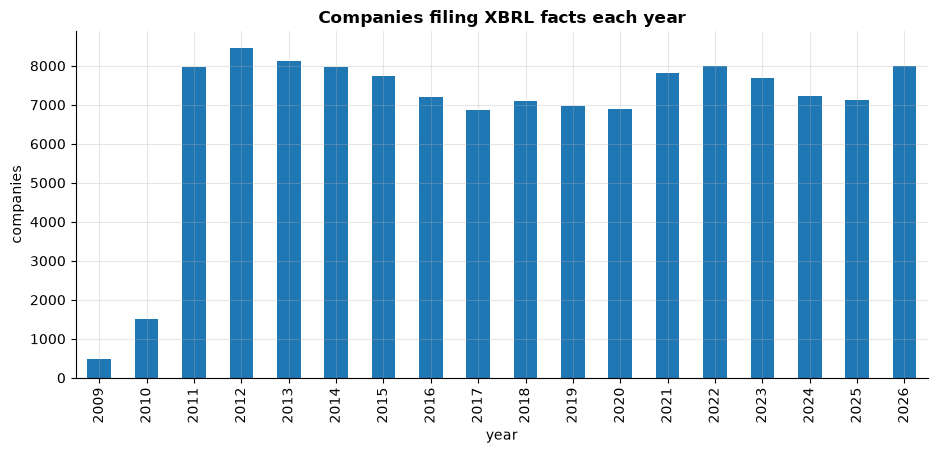

In [2]:
status = edgar.status()
print(f"companies: {status['companies']:,}   facts on disk: {status['facts_bytes'] / 1e9:.2f} GB")
print(f"bulk file: {status['bulk_last_modified']}   daily sync through: {status['sync_through']}")
with timed("scan every fact"):
    by_year = (edgar.scan().group_by(pl.col("filed").dt.year().alias("year"))
               .agg(pl.len().alias("facts"), pl.col("cik").n_unique().alias("companies"),
                    pl.col("accn").n_unique().alias("filings"))
               .sort("year").collect())
ax = by_year.filter(pl.col("year") >= 2009).to_pandas().set_index("year")[["companies"]].plot.bar(
    title="Companies filing XBRL facts each year", legend=False)
ax.set_ylabel("companies");

XBRL became mandatory in 2009 for the largest filers and in 2011 for everyone else, so EDGAR
fundamentals start there. Items map to several tags in priority order (`CONCEPTS`):

In [3]:
pl.DataFrame([(k, c.kind, c.unit, len(c.tags), c.tags[0]) for k, c in CONCEPTS.items()],
             schema=["item", "kind", "unit", "tags", "first tag"], orient="row")

item,kind,unit,tags,first tag
str,str,str,i64,str
"""revenue""","""flow""","""currency""",13,"""us-gaap:Revenues"""
"""gross_profit""","""flow""","""currency""",2,"""us-gaap:GrossProfit"""
"""operating_income""","""flow""","""currency""",2,"""us-gaap:OperatingIncomeLoss"""
"""net_income""","""flow""","""currency""",5,"""us-gaap:NetIncomeLoss"""
"""eps_basic""","""per_share""","""currency/shares""",2,"""us-gaap:EarningsPerShareBasic"""
"""eps_diluted""","""per_share""","""currency/shares""",2,"""us-gaap:EarningsPerShareDiluted"""
"""operating_cash_flow""","""flow""","""currency""",3,"""us-gaap:NetCashProvidedByUsedInOperatingActiv…"
"""capex""","""flow""","""currency""",2,"""us-gaap:PaymentsToAcquirePropertyPlantAndEqui…"
"""dividends_paid""","""flow""","""currency""",3,"""us-gaap:PaymentsOfDividendsCommonStock"""


## 2 · One company, point in time

Apple's quarterly revenue. `filed` is when the number first appeared; `available_from` is the
day after (filings are often accepted after the close). Q4 is not reported in a 10-Q: it is
derived as annual minus nine months (`source = derived`).

When a company changes tags (many did with the 2018 revenue standard), older periods appear
under the new tag only in later filings' comparison columns. Each period therefore takes the
value that was **known first, whatever its tag**; tag priority only breaks ties within one filing.

In [4]:
aapl = edgar.series(["revenue", "net_income", "operating_cash_flow"], ciks=320193)
aapl.filter(pl.col("item") == "revenue", pl.col("period") == "quarter").tail(8).select(
    "end", (pl.col("value") / 1e9).round(2).alias("revenue_bn"), (pl.col("ttm") / 1e9).round(1).alias("ttm_bn"),
    "filed", "available_from", "source")

end,revenue_bn,ttm_bn,filed,available_from,source
date,f64,f64,date,date,str
2024-09-28,94.93,391.0,2024-11-01,2024-11-02,"""derived"""
2024-12-28,124.3,395.8,2025-01-31,2025-02-01,"""reported"""
2025-03-29,95.36,400.4,2025-05-02,2025-05-03,"""reported"""
2025-06-28,94.04,408.6,2025-08-01,2025-08-02,"""reported"""
2025-09-27,102.47,416.2,2025-10-31,2025-11-01,"""derived"""
2025-12-27,143.76,435.6,2026-01-30,2026-01-31,"""reported"""
2026-03-28,111.18,451.4,2026-05-01,2026-05-02,"""reported"""
2026-06-27,109.42,466.8,2026-07-31,2026-08-01,"""reported"""


`as_of(day)` returns what was knowable on that day: the newest value per item whose filing
came before it, plus shares outstanding.

In [5]:
edgar.as_of("2020-06-30", ciks=320193, items=["revenue", "net_income", "assets", "eps_diluted"]).select(
    "item", "period", "end", "value", "ttm", "filed")

item,period,end,value,ttm,filed
str,str,date,f64,f64,date
"""assets""","""instant""",2020-03-28,3.2040e11,null,2020-05-01
"""eps_diluted""","""quarter""",2020-03-28,2.55,null,2020-05-01
"""net_income""","""quarter""",2020-03-28,1.1249e10,5.7215e10,2020-05-01
"""revenue""","""quarter""",2020-03-28,5.8313e10,2.6798e11,2020-05-01
"""shares""","""instant""",2020-03-28,4.3240e9,null,2020-05-01


## 3 · How often numbers get restated

The same quarter is reported again in later filings (as a comparison column), sometimes with
a different value: reclassifications, discontinued operations, corrections. Comparing the
first-filed value with the latest one, for every company's quarterly revenue:

revenue for every company, first-filed and latest: 6.12 s
348,318 company-quarters; changed by more than 0.5% later: 9.2%


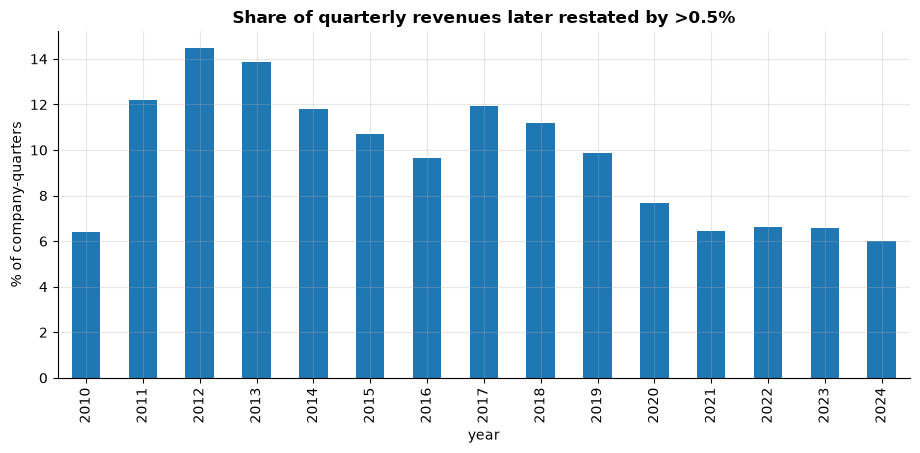

In [6]:
with timed("revenue for every company, first-filed and latest"):
    first = edgar.series("revenue").filter(pl.col("period") == "quarter")
    latest = edgar.series("revenue", policy="latest").filter(pl.col("period") == "quarter")
j = first.join(latest, on=["cik", "unit", "end"], suffix="_latest").filter(pl.col("value").abs() > 0)
j = j.with_columns(((pl.col("value_latest") - pl.col("value")) / pl.col("value").abs()).alias("change"))
restated = j.with_columns((pl.col("change").abs() > 0.005).alias("restated"))
print(f"{j.height:,} company-quarters; changed by more than 0.5% later: {restated['restated'].mean() * 100:.1f}%")
yearly = (restated.group_by(pl.col("end").dt.year().alias("year")).agg((pl.col("restated").mean() * 100).alias("pct"))
          .filter(pl.col("year").is_between(2010, 2024)).sort("year"))
ax = yearly.to_pandas().set_index("year")["pct"].plot.bar(title="Share of quarterly revenues later restated by >0.5%")
ax.set_ylabel("% of company-quarters");

Recent quarters have had less time to be restated. With `policy="first"` (the default) a
backtest sees the numbers as first published; `policy="latest"` is fine for live use.

## 4 · Shares outstanding

Massive has no share-count history; EDGAR does. One concept per company: the cover page count,
the balance-sheet count, or the weighted average, whichever appears in most filings. Values
are as reported, so splits show up as jumps (Apple's 4:1 in 2020):

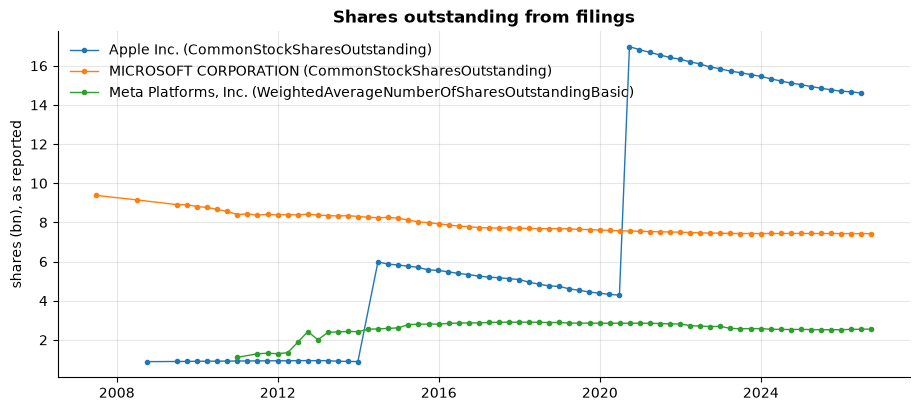

In [7]:
sh = edgar.shares([320193, 1326801, 789019])
names = dict(edgar.companies().select("cik", "name").iter_rows())
fig, ax = plt.subplots()
for (cik,), g in sh.group_by("cik", maintain_order=True):
    ax.plot(g["end"].to_list(), (g["shares"] / 1e9).to_list(), marker=".", lw=1, label=f"{names[cik]} ({g['tag'][0].split(':')[1]})")
ax.set_ylabel("shares (bn), as reported")
ax.set_title("Shares outstanding from filings")
ax.legend();

Meta has two share classes; company facts leave out per-class cover-page counts, so its series
is the weighted average of all classes. Which concept companies end up with:

In [8]:
with timed("shares for every company"):
    all_sh = edgar.shares()
all_sh.group_by("cik").agg(pl.col("tag").first()).group_by("tag").len().sort("len", descending=True)

shares for every company: 1.00 s


tag,len
str,u32
"""dei:EntityCommonStockSharesOutstanding""",13304
"""us-gaap:WeightedAverageNumberOfSharesOutstand…",1509
"""us-gaap:CommonStockSharesOutstanding""",1097


## 5 · Coverage of the tradable universe

The security master in `massive-subspace-stream` knows each traded security's CIK on each day.
For common stocks in the universe on a few dates: does EDGAR know the company, and were
revenue and a share count usable that day?

In [9]:
rows = []
for day in (date(2011, 6, 30), date(2014, 6, 30), date(2018, 6, 29), date(2022, 6, 30), date(2026, 10, 30)):
    u = massive.universe(day, types=["CS"])
    ciks = u["cik"].drop_nulls().unique().to_list()
    known = set(edgar.companies().filter(pl.col("cik").is_in(ciks))["cik"])
    snap = edgar.as_of(day, ciks=ciks, items=["revenue"])
    has_rev = set(snap.filter(pl.col("item") == "revenue")["cik"])
    has_sh = set(snap.filter(pl.col("item") == "shares")["cik"])
    rows.append((day, u.height, len(ciks), len(known), len(has_rev), len(has_sh)))
cov = pl.DataFrame(rows, schema=["day", "common_stocks", "with_cik", "in_edgar", "revenue_usable", "shares_usable"], orient="row")
cov.with_columns(*[(pl.col(c) / pl.col("with_cik") * 100).round(1).alias(f"{c}_pct") for c in ("in_edgar", "revenue_usable", "shares_usable")])

day,common_stocks,with_cik,in_edgar,revenue_usable,shares_usable,in_edgar_pct,revenue_usable_pct,shares_usable_pct
date,i64,i64,i64,i64,i64,f64,f64,f64
2011-06-30,4575,4403,3771,1254,1291,85.6,28.5,29.3
2014-06-30,5026,4853,4326,3379,3524,89.1,69.6,72.6
2018-06-29,4533,4420,4327,3793,3933,97.9,85.8,89.0
2022-06-30,5748,5647,5621,4556,4806,99.5,80.7,85.1
2026-10-30,5163,5046,5017,4242,4589,99.4,84.1,90.9


What is missing, and why:
- **2011**: small companies only started XBRL with periods after mid-2011.
- **Foreign filers** (20-F/40-F) started XBRL with fiscal 2014-2015, which holds back 2014.
- **Closed-end funds and BDCs** (typed as common stock by Massive) filed no XBRL statements
  for most of this history.
- **No revenue line**: shells, SPACs and early-stage biotechs; some banks and insurers use tags
  outside the map.
- Annual-only filers drop out once their last fiscal year is more than 400 days old.

## 6 · Cross-check against Massive's financials

For the largest current common stocks, compare Massive's quarterly revenue with EDGAR's
first-filed value for the same quarter, and Massive's `filing_date` with the original filing.

15,463 company-quarters from 290 companies
same revenue (within 0.5%): 86.3%
Massive's filing_date later than the original filing: 90.6% (median lag when late: 365 days)


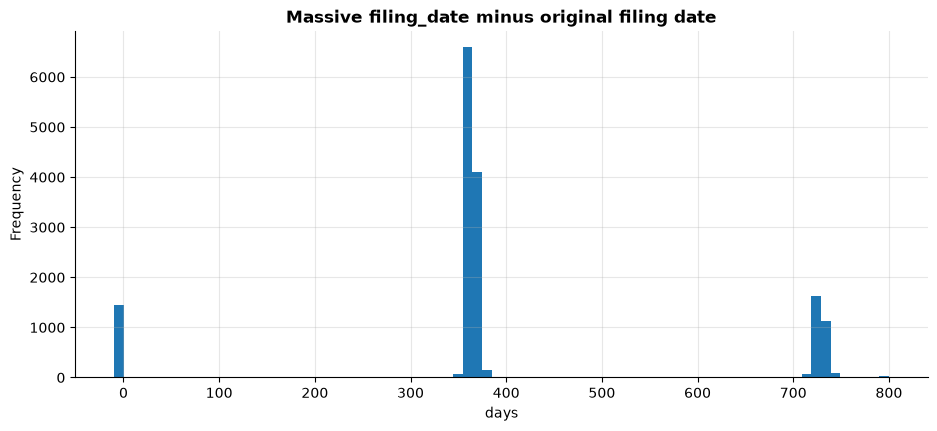

In [10]:
u = massive.universe(date(2026, 10, 30), types=["CS"]).with_columns((pl.col("close") * pl.col("volume")).alias("dv"))
top = u.sort("dv", descending=True).head(300).filter(pl.col("cik").is_not_null())
m = (massive.financials("income").filter(pl.col("timeframe") == "quarterly", pl.col("cik").is_in(top["cik"].to_list()))
     .select("cik", pl.col("period_end").alias("end"), pl.col("revenue").alias("massive_revenue"),
             pl.col("filing_date").alias("massive_filing_date")))
e = edgar.series("revenue", ciks=top["cik"].to_list()).filter(pl.col("period") == "quarter").select(
    "cik", "end", pl.col("value").alias("edgar_revenue"), pl.col("filed").alias("edgar_first_filed"))
cmp = m.join(e, on=["cik", "end"]).filter(pl.col("massive_revenue").is_not_null() & (pl.col("edgar_revenue") != 0))
cmp = cmp.with_columns(
    ((pl.col("massive_revenue") / pl.col("edgar_revenue") - 1).abs() < 0.005).alias("same_value"),
    (pl.col("massive_filing_date") - pl.col("edgar_first_filed")).dt.total_days().alias("massive_date_lag_days"))
print(f"{cmp.height:,} company-quarters from {cmp['cik'].n_unique()} companies")
print(f"same revenue (within 0.5%): {cmp['same_value'].mean() * 100:.1f}%")
print(f"Massive's filing_date later than the original filing: {(cmp['massive_date_lag_days'] > 0).mean() * 100:.1f}% "
      f"(median lag when late: {cmp.filter(pl.col('massive_date_lag_days') > 0)['massive_date_lag_days'].median():.0f} days)")
ax = cmp["massive_date_lag_days"].clip(-10, 800).to_pandas().plot.hist(bins=80, title="Massive filing_date minus original filing date")
ax.set_xlabel("days");

The values mostly agree; the dates do not. Massive dates most older quarters by a filing a
year or two later (the spikes near 365 and 730 days), which is why backtests should take
fundamentals from EDGAR.

## Takeaways
- `EdgarStore.series()` / `as_of()` give first-filed values usable from the day after filing.
- Restatements are common enough (several percent of quarters) to matter in backtests.
- Shares outstanding history exists only here; it is as reported (not split-adjusted).
- Joining to tickers goes through the security master's CIK; market cap and size universes are
  the next step (a package that uses both sources).